Fix original counts object for the melanoma data set for use it has refferance for t cells sub groups 

In [1]:
import tifffile
import os
from spatialdata.models import Image2DModel
import spatialdata_io
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point
import numpy as np
from spatialdata.models import ShapesModel
from spatialdata import transform
import anndata
import scanpy as sc
from spatialdata import SpatialData
from spatialdata import polygon_query
from spatialdata import bounding_box_query
from napari_spatialdata import Interactive
from spatialdata.models import TableModel
from spatialdata_plot.pl.utils import set_zero_in_cmap_to_transparent
from spatialdata import SpatialData
import spatialdata as sd
from scipy import ndimage as ndi
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib as mpl
from spatialdata.transformations import (
    BaseTransformation,
    Identity,
    Sequence,
    align_elements_using_landmarks,
    get_transformation,
    set_transformation,
    Affine,
    Translation
)
import pickle
import sys
import gc
from tqdm import tqdm
import re
import squidpy as sq
import random

In [8]:
path_sdata = '/data/HiTIF/data/spatial_data_napari/rosa_melanoma/data/'
path_zarr = os.path.join(path_sdata,'slide_1_left.zarr')
sdata_1 = sd.read_zarr(path_zarr)
path_sdata = '/data/HiTIF/data/spatial_data_napari/rosa_melanoma/data/'
path_zarr = os.path.join(path_sdata,'slide_2_right.zarr')
sdata_2 = sd.read_zarr(path_zarr)

/tmp/ipykernel_3260723/3079594056.py:3: UserWarning: SpatialData is not stored in the most current format. If you want to use Zarr v3, please write the store to a new location using `sdata.write()`.
  sdata_1 = sd.read_zarr(path_zarr)
no parent found for <ome_zarr.reader.Label object at 0x155436ee1e90>: None
/vf/users/kanferg/conda_v1/envs/spatiocore_spatial_env/lib/python3.11/site-packages/spatialdata/_core/spatialdata.py:170: UserWarning: The table is annotating 'cell_circles', which is not present in the SpatialData object.
  self.validate_table_in_spatialdata(v)
/vf/users/kanferg/conda_v1/envs/spatiocore_spatial_env/lib/python3.11/site-packages/spatialdata/_core/spatialdata.py:170: UserWarning: The table is annotating 'cells', which is not present in the SpatialData object.
  self.validate_table_in_spatialdata(v)
/tmp/ipykernel_3260723/3079594056.py:6: UserWarning: SpatialData is not stored in the most current format. If you want to use Zarr v3, please write the store to a new loca

In [29]:
sdata_2

/vf/users/kanferg/conda_v1/envs/spatiocore_spatial_env/lib/python3.11/site-packages/zarr/core/group.py:3559: ZarrUserWarning: Object at zmetadata is not recognized as a component of a Zarr hierarchy.
  warnings.warn(


SpatialData object, with associated Zarr store: /vf/users/HiTIF/data/spatial_data_napari/rosa_melanoma/data/slide_2_right.zarr
├── Images
│     ├── 'codex_image_R': DataTree[cyx] (32, 42480, 30720), (32, 21240, 15360), (32, 10620, 7680), (32, 5310, 3840)
│     └── 'xenium_image_R': DataTree[cyx] (5, 95169, 48375), (5, 47584, 24187), (5, 23792, 12093), (5, 11896, 6046), (5, 5948, 3023)
├── Shapes
│     ├── 'cola1_R': GeoDataFrame shape: (166312, 2) (2D shapes)
│     └── 'xenium_all_R': GeoDataFrame shape: (345067, 6) (2D shapes)
└── Tables
      ├── 'codex_table': AnnData (264993, 1)
      └── 'xenium_table': AnnData (362669, 5006)
with coordinate systems:
    ▸ 'codex_coor', with elements:
        codex_image_R (Images)
    ▸ 'global', with elements:
        xenium_image_R (Images)
    ▸ 'slide2_right', with elements:
        codex_image_R (Images), xenium_image_R (Images), cola1_R (Shapes), xenium_all_R (Shapes)

In [23]:
gdf = sdata_1['xenium_all_L']
gdf = gdf.loc[gdf['cluster'].isin(['Cytotoxic T-cells','Proliferating T-cells','Exhausting T-cells'])]
map_slide_1 = dict(zip(gdf.index, gdf['cluster']))

In [28]:
ad_1 = sdata_1['xenium_table'].copy()
ad_1.obs['cell_type'] = ad_1.obs['cell_id'].map(map_slide_1).fillna('remove')
ad_1 = ad_1[ad_1.obs['cell_type'] != 'remove']
ad_1.obs = ad_1.obs[['cell_type']]

View of AnnData object with n_obs × n_vars = 25667 × 5006
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level', 'cell_labels', 'cell_type'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatialdata_attrs'
    obsm: 'spatial'

In [30]:
gdf = sdata_2['xenium_all_R']
gdf = gdf.loc[gdf['cluster'].isin(['Cytotoxic T-cells','Proliferating T-cells','Exhausting T-cells'])]
map_slide_2 = dict(zip(gdf.index, gdf['cluster']))

In [31]:
ad_2 = sdata_2['xenium_table'].copy()
ad_2.obs['cell_type'] = ad_2.obs['cell_id'].map(map_slide_2).fillna('remove')
ad_2 = ad_2[ad_2.obs['cell_type'] != 'remove']
ad_2.obs = ad_2.obs[['cell_type']]

In [33]:
import anndata as ad
adata = ad.concat([ad_1, ad_2])

/vf/users/kanferg/conda_v1/envs/spatiocore_spatial_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1878: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


In [35]:
path_nb = '/data/HiTIF/data/spatialomics/neuroblastoma/data/andata_orig'
adata.write_h5ad(os.path.join(path_nb, 'adata_melanoma_tcells.h5ad'))

In [2]:
import tacco as tc
import scanpy as sc
import numpy as np

import os
from PIL import Image
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.backends.backend_pdf import PdfPages
import seaborn as sns
import random
import pandas as pd
import pickle
import sys

sys.path.insert(
    0,
    "/data/kanferg/Sptial_Omics/projects/NatalieLab/liver_cancer/spatialomicstoolkit"
)

from spat_functions.anno_plot import *

import pickle
import h5py
import os
from sklearn.model_selection import train_test_split
import scipy.sparse as sp
import anndata as ad

In [3]:
pathout = '/data/HiTIF/data/spatialomics/neuroblastoma/data/andata_orig'
adata_mel_t = sc.read_h5ad(os.path.join(pathout, "adata_melanoma_tcells.h5ad"))

/vf/users/kanferg/conda_v1/envs/tacco_env/lib/python3.13/site-packages/anndata/_core/anndata.py:1791: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


In [30]:
adata_mel_t.obs_names_make_unique()

In [5]:
pathad = '/data/HiTIF/data/spatialomics/neuroblastoma/data/andata_orig'
adata = sc.read_h5ad(os.path.join(pathad, "adata_nb_processed_v2.h5ad"))

In [31]:
adata.obs_names_make_unique()

In [33]:
andata_nb_t = adata[adata.obs['annotation_v1'].isin(["CD8_Cytotoxic_TCell_PartiallyExhausted"])].copy()

In [34]:
# select genes based on melanoma
andata_nb_t.X = andata_nb_t.layers['raw_counts']

In [35]:
print(adata_mel_t.X.min(), adata_mel_t.X.max())
print(andata_nb_t.X.min(), andata_nb_t.X.max())


0.0 135.0
0.0 157.0


In [36]:
import scipy.sparse as sp

from sklearn.model_selection import train_test_split

TCELL_TYPES = [
    "Cytotoxic T-cells",
    "Proliferating T-cells",
    "Exhausting T-cells",
]

RANDOM_STATE = 1948

In [37]:
common_genes = adata_mel_t.var_names.intersection(
    andata_nb_t.var_names,
    sort=False
)
adata_mel_t = adata_mel_t[:, common_genes].copy()
andata_nb_t = andata_nb_t[:, common_genes].copy()

In [ ]:
ref_cells, test_cells = train_test_split(
    adata_mel_t.obs_names,
    test_size=0.5,
    stratify=adata_mel_t.obs['cell_type'],
    random_state=RANDOM_STATE
)

# balance the test set to equal counts per class; reference set is left untouched
test_labels = adata_mel_t.obs.loc[test_cells, ['cell_type']]
min_count = test_labels['cell_type'].value_counts().min()
test_cells = (
    test_labels.groupby('cell_type', group_keys=False)
    .apply(lambda d: d.sample(n=min_count, random_state=RANDOM_STATE))
    .index
)

adata_mel_t.obs['split'] = 'test'
adata_mel_t.obs.loc[ref_cells, 'split'] = 'reference'


In [39]:
adata_mel_t.obs_names

Index(['4065', '4378', '4382', '4891', '4892', '4894', '4901', '5037', '5059',
       '5134',
       ...
       '361502', '361892', '361931', '362092', '362135', '362194', '362222',
       '362232', '362277', '362629'],
      dtype='object', length=62150)

In [40]:
rdata = adata_mel_t[ref_cells].copy()
rdata.obs = rdata.obs[['cell_type']].copy()
# rdata.uns.clear()
# rdata.obsm.clear()
# rdata.varm.clear()
# rdata.obsp.clear()
# rdata.layers.clear()

In [41]:
adata_mel_t_test = adata_mel_t[test_cells].copy()
adata_mel_t_test.obs = adata_mel_t_test.obs[['cell_type']].copy()
adata_mel_t_test.obs['true_label'] = adata_mel_t_test.obs['cell_type'].astype(str)
adata_mel_t_test.obs['dataset'] = 'mel'
adata_mel_t_test.obs['split'] = 'test'
adata_mel_t_test.uns.clear()
adata_mel_t_test.obsm.clear()
adata_mel_t_test.varm.clear()
adata_mel_t_test.obsp.clear()
adata_mel_t_test.layers.clear()

In [42]:
adata_mel_t_test

AnnData object with n_obs × n_vars = 31075 × 5006
    obs: 'cell_type', 'true_label', 'dataset', 'split'

In [43]:
andata_nb_t_predict = andata_nb_t.copy()
andata_nb_t_predict.obs.rename(columns={'annotation_v1': 'cell_type'}, inplace=True)
andata_nb_t_predict.obs = andata_nb_t_predict.obs[['cell_type']].copy()
andata_nb_t_predict.obs['true_label'] = pd.NA
andata_nb_t_predict.obs['dataset'] = 'nb'
andata_nb_t_predict.obs['split'] = 'prediction'
andata_nb_t_predict.uns.clear()
andata_nb_t_predict.obsm.clear()
andata_nb_t_predict.varm.clear()
andata_nb_t_predict.obsp.clear()
andata_nb_t_predict.layers.clear()

In [44]:
andata_nb_t_predict.obs_names = 'nb_' + andata_nb_t_predict.obs_names.astype(str)
adata_mel_t_test.obs_names = 'mel_' + adata_mel_t_test.obs_names.astype(str)

In [45]:
adata = ad.concat([adata_mel_t_test, andata_nb_t_predict])

In [46]:
print(adata.X.min(), adata.X.max())
print(rdata.X.min(), rdata.X.max())

print((adata.X.sum(axis=1) == 0).sum())
print((rdata.X.sum(axis=1) == 0).sum())

0.0 157.0
0.0 114.0
0
0


In [58]:
import tacco as tc
import pandas as pd

from sklearn.metrics import precision_recall_curve
from sklearn.metrics import average_precision_score

epsilon_values = [
    0.005,
    0.01,
    0.05,
    0.1,
    0.5,
    1.0,
    2.0, 5.0, 10.0
]

lamb_values = [
    0.0001,
    0.001,
    0.01,
    0.1,
    1.0,
    10.0,
    100.0
]

cell_types = [
    'Cytotoxic T-cells',
    'Proliferating T-cells',
    'Exhausting T-cells'
]

pr_results = []
ap_results = []
tacco_results = {}

for epsilon in epsilon_values:
    for lamb in lamb_values:

        print('epsilon:', epsilon, 'lamb:', lamb)

        adata_tmp = adata.copy()

        try:

            tc.tl.annotate(
                adata_tmp,
                rdata,
                annotation_key='cell_type',
                result_key='tacco_labels',
                counts_location='X',
                method='OT',
                epsilon=epsilon,
                lamb=lamb,
                bisections=0,
                platform_iterations=0,
                remove_zero_cells=True,
                remove_constant_genes=True,
                min_counts_per_cell=1,
                min_counts_per_gene=1,
                assume_valid_counts=True,
                verbose=0
            )

        except Exception as e:

            print('FAILED:', epsilon, lamb, e)

            continue

        setting = f'e{epsilon}_l{lamb}'

        tacco_results[setting] = adata_tmp.obsm['tacco_labels'].copy()

        test_mask = adata_tmp.obs['split'] == 'test'

        y_true = adata_tmp.obs.loc[test_mask, 'true_label']

        scores = adata_tmp.obsm['tacco_labels'].loc[test_mask]

        for cell_type in cell_types:

            y_binary = (y_true == cell_type).astype(int)

            y_score = scores[cell_type]

            precision, recall, thresholds = precision_recall_curve(
                y_binary,
                y_score
            )

            ap = average_precision_score(
                y_binary,
                y_score
            )

            tmp = pd.DataFrame({
                'precision': precision,
                'recall': recall,
                'cell_type': cell_type,
                'epsilon': epsilon,
                'lamb': lamb,
                'setting': setting
            })

            pr_results.append(tmp)

            ap_results.append({
                'cell_type': cell_type,
                'epsilon': epsilon,
                'lamb': lamb,
                'setting': setting,
                'AP': ap
            })

pr_results = pd.concat(
    pr_results,
    ignore_index=True
)

ap_results = pd.DataFrame(ap_results)

epsilon: 0.005 lamb: 0.0001
epsilon: 0.005 lamb: 0.001
epsilon: 0.005 lamb: 0.01
epsilon: 0.005 lamb: 0.1
epsilon: 0.005 lamb: 1.0
epsilon: 0.005 lamb: 10.0
epsilon: 0.005 lamb: 100.0
epsilon: 0.01 lamb: 0.0001
epsilon: 0.01 lamb: 0.001
epsilon: 0.01 lamb: 0.01
epsilon: 0.01 lamb: 0.1
epsilon: 0.01 lamb: 1.0
epsilon: 0.01 lamb: 10.0
epsilon: 0.01 lamb: 100.0
epsilon: 0.05 lamb: 0.0001
epsilon: 0.05 lamb: 0.001
epsilon: 0.05 lamb: 0.01
epsilon: 0.05 lamb: 0.1
epsilon: 0.05 lamb: 1.0
epsilon: 0.05 lamb: 10.0
epsilon: 0.05 lamb: 100.0
epsilon: 0.1 lamb: 0.0001
epsilon: 0.1 lamb: 0.001
epsilon: 0.1 lamb: 0.01
epsilon: 0.1 lamb: 0.1
epsilon: 0.1 lamb: 1.0
epsilon: 0.1 lamb: 10.0
epsilon: 0.1 lamb: 100.0
epsilon: 0.5 lamb: 0.0001
epsilon: 0.5 lamb: 0.001
epsilon: 0.5 lamb: 0.01
epsilon: 0.5 lamb: 0.1
epsilon: 0.5 lamb: 1.0
epsilon: 0.5 lamb: 10.0
epsilon: 0.5 lamb: 100.0
epsilon: 1.0 lamb: 0.0001
epsilon: 1.0 lamb: 0.001
epsilon: 1.0 lamb: 0.01
epsilon: 1.0 lamb: 0.1
epsilon: 1.0 lamb: 1.0
e

/tmp/ipykernel_3262993/2850599189.py:35: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


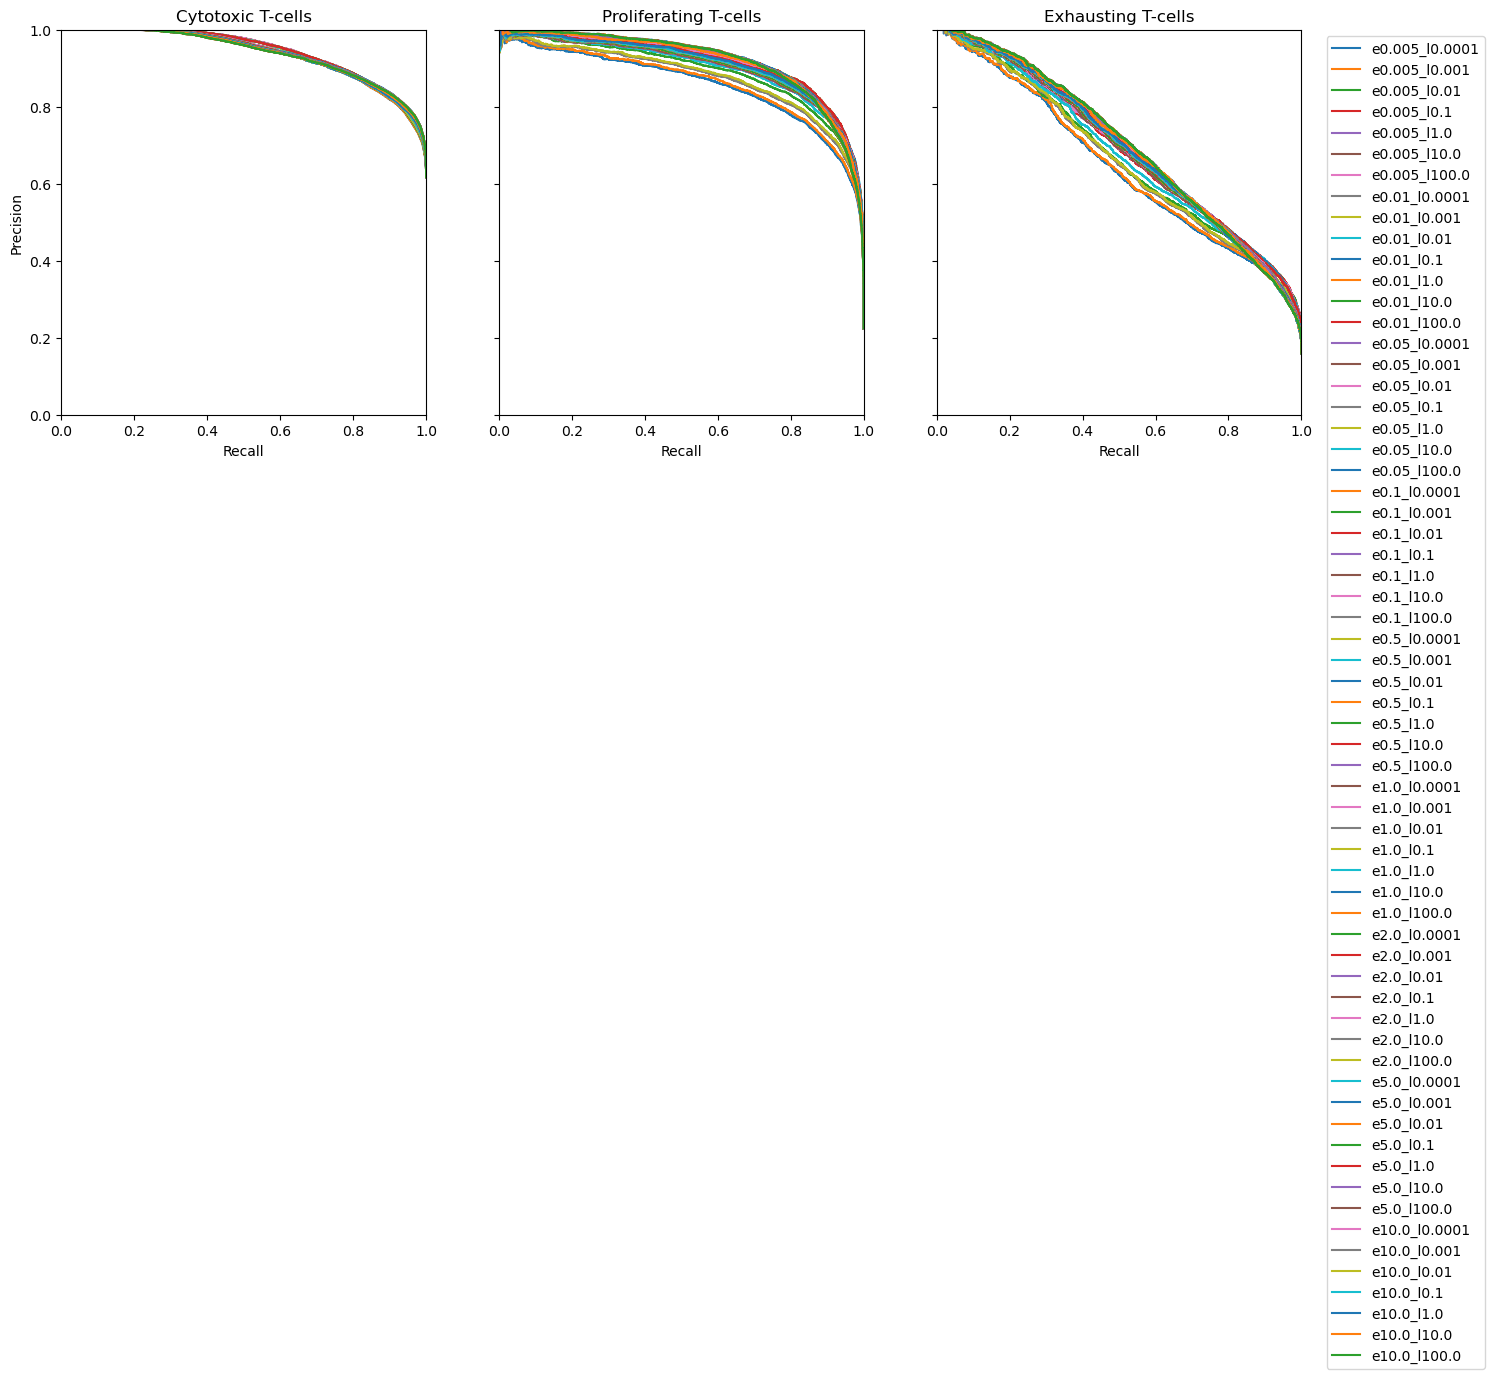

In [62]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True)

for ax, cell_type in zip(axes, cell_types):

    df = pr_results[
        pr_results['cell_type'] == cell_type
    ]

    for setting in df['setting'].unique():

        d = df[
            df['setting'] == setting
        ]

        ax.plot(
            d['recall'],
            d['precision'],
            label=setting
        )

    ax.set_title(cell_type)
    ax.set_xlabel('Recall')
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)

axes[0].set_ylabel('Precision')

axes[-1].legend(
    bbox_to_anchor=(1.05, 1),
    loc='upper left'
)

plt.tight_layout()
plt.show()

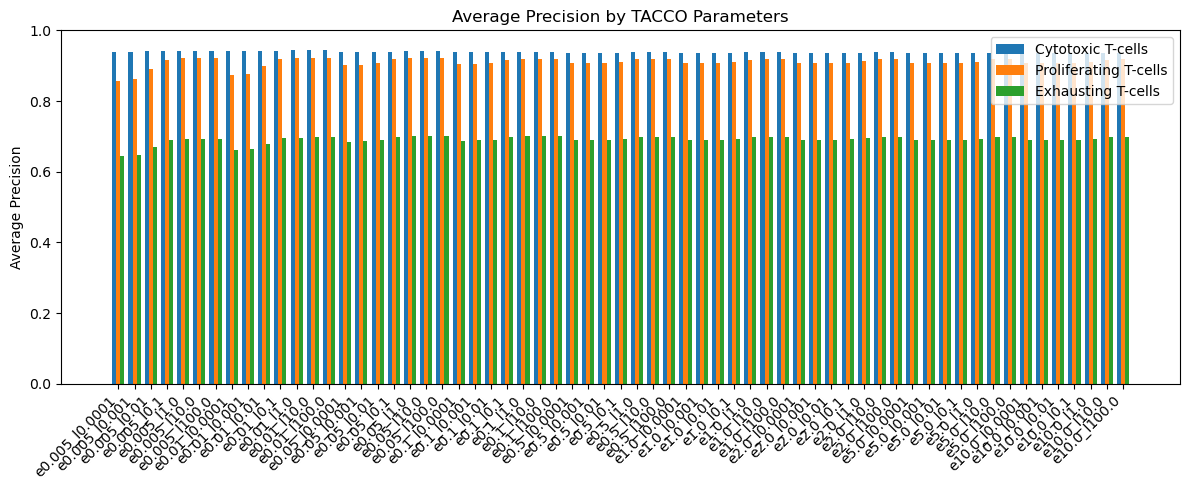

In [63]:
fig, ax = plt.subplots(figsize=(12, 5))

settings = ap_results['setting'].unique()

x = range(len(settings))

width = 0.25

for i, cell_type in enumerate(cell_types):

    df = ap_results[
        ap_results['cell_type'] == cell_type
    ].set_index('setting').loc[settings]

    ax.bar(
        [j + i * width for j in x],
        df['AP'],
        width=width,
        label=cell_type
    )

ax.set_xticks(
    [j + width for j in x]
)

ax.set_xticklabels(
    settings,
    rotation=45,
    ha='right'
)

ax.set_ylabel('Average Precision')
ax.set_ylim(0, 1)
ax.set_title('Average Precision by TACCO Parameters')
ax.legend()

plt.tight_layout()
plt.show()

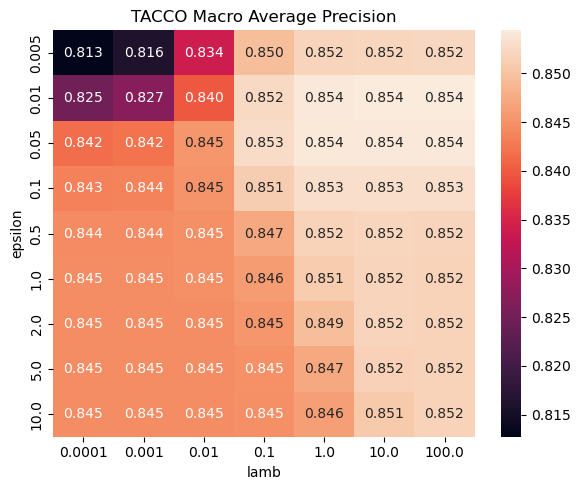

In [64]:
macro_ap = ap_results.groupby(
    ['epsilon', 'lamb', 'setting']
)['AP'].mean().reset_index()

macro_ap = macro_ap.rename(
    columns={'AP': 'macro_AP'}
)

macro_ap = macro_ap.sort_values(
    'macro_AP',
    ascending=False
)

macro_ap

import matplotlib.pyplot as plt
import seaborn as sns

heatmap_data = macro_ap.pivot(
    index='epsilon',
    columns='lamb',
    values='macro_AP'
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='.3f'
)

plt.title('TACCO Macro Average Precision')
plt.xlabel('lamb')
plt.ylabel('epsilon')

plt.tight_layout()
plt.show()

In [67]:
EPSILON_SEL = 0.01
LAMB_SEL = 1.0

# rebuild the test set from the class-balanced test_cells; reference (rdata) is unchanged
adata_mel_t_test = adata_mel_t[test_cells].copy()
adata_mel_t_test.obs = adata_mel_t_test.obs[['cell_type']].copy()
adata_mel_t_test.obs['true_label'] = adata_mel_t_test.obs['cell_type'].astype(str)
adata_mel_t_test.obs['dataset'] = 'mel'
adata_mel_t_test.obs['split'] = 'test'
adata_mel_t_test.uns.clear()
adata_mel_t_test.obsm.clear()
adata_mel_t_test.varm.clear()
adata_mel_t_test.obsp.clear()
adata_mel_t_test.layers.clear()
adata_mel_t_test.obs_names = 'mel_' + adata_mel_t_test.obs_names.astype(str)

adata = ad.concat([adata_mel_t_test, andata_nb_t_predict])

adata_tmp = adata.copy()

tc.tl.annotate(
    adata_tmp,
    rdata,
    annotation_key='cell_type',
    result_key='tacco_labels',
    counts_location='X',
    method='OT',
    epsilon=EPSILON_SEL,
    lamb=LAMB_SEL,
    bisections=0,
    platform_iterations=0,
    remove_zero_cells=True,
    remove_constant_genes=True,
    min_counts_per_cell=1,
    min_counts_per_gene=1,
    assume_valid_counts=True,
    verbose=0
)

test_mask = adata_tmp.obs['split'] == 'test'
y_true = adata_tmp.obs.loc[test_mask, 'true_label']
scores = adata_tmp.obsm['tacco_labels'].loc[test_mask]

pr_rows = []
ap_sel = {}

for cell_type in cell_types:

    y_binary = (y_true == cell_type).astype(int)
    y_score = scores[cell_type]

    precision, recall, thresholds = precision_recall_curve(y_binary, y_score)
    ap = average_precision_score(y_binary, y_score)

    pr_rows.append(pd.DataFrame({
        'precision': precision,
        'recall': recall,
        'cell_type': cell_type,
    }))
    ap_sel[cell_type] = ap

pr_sel = pd.concat(pr_rows, ignore_index=True)
ap_sel = pd.Series(ap_sel)


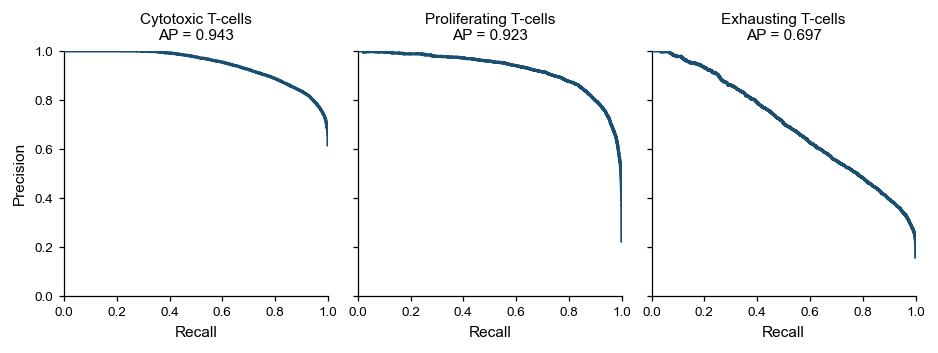

Saved: figures/tacco_pr_curves_eps0.01_lamb1.0.pdf
Saved: figures/tacco_pr_curves_eps0.01_lamb1.0.png


In [69]:
import os
import matplotlib as mpl
import matplotlib.pyplot as plt

PUBLICATION_RC = {
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial"],
    "font.size": 8,
    "axes.labelsize": 8.5,
    "axes.titlesize": 8.5,
    "xtick.labelsize": 7.5,
    "ytick.labelsize": 7.5,
    "legend.fontsize": 7.5,
    "axes.linewidth": 0.7,
    "xtick.major.width": 0.7,
    "ytick.major.width": 0.7,
    "xtick.major.size": 2.5,
    "ytick.major.size": 2.5,
    "axes.grid": False,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
    "figure.dpi": 130,
    "savefig.facecolor": "white",
}

CURVE_COLOR = "#1B4F72"

with mpl.rc_context(PUBLICATION_RC):

    fig, axes = plt.subplots(
        1, 3, figsize=(7.1, 2.6), sharex=True, sharey=True,
        constrained_layout=True,
    )

    for i, (ax, cell_type) in enumerate(zip(axes, cell_types)):

        df = pr_sel[pr_sel['cell_type'] == cell_type]
        ap = ap_sel.loc[cell_type]

        ax.plot(
            df['recall'], df['precision'],
            color=CURVE_COLOR, lw=1.8, zorder=3,
        )

        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.set_xlabel('Recall')
        if i == 0:
            ax.set_ylabel('Precision')

        ax.set_title(f'{cell_type}\nAP = {ap:.3f}', fontsize=8.5)

        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

    outdir = 'figures'
    os.makedirs(outdir, exist_ok=True)
    pdf_path = os.path.join(outdir, 'tacco_pr_curves_eps0.01_lamb1.0.pdf')
    png_path = os.path.join(outdir, 'tacco_pr_curves_eps0.01_lamb1.0.png')

    fig.savefig(pdf_path, bbox_inches='tight')
    fig.savefig(png_path, dpi=600, bbox_inches='tight')

    plt.show()

print(f'Saved: {pdf_path}')
print(f'Saved: {png_path}')


In [73]:
adata_tmp.obs['split'].unique()

array(['test', 'prediction'], dtype=object)

In [ ]:
adata_nb_pred = adata_tmp[adata_tmp.obs['split'].isin(['prediction'])].copy()
adata_ = adata_tmp[adata_tmp.obs['split'].isin(['prediction'])].copy()

In [ ]:
adata.obs['annotation_test'] = tc.utils.get_maximum_annotation(
    adata,
    obsm_key='tacco_labels'
)

Paramters for use are clear lets rerun tacoo